In [ ]:

from google.colab import files

uploaded = files.upload()


Saving drive-download-20261110T054224Z-1-001.zip to drive-download-20261110T054224Z-1-001.zip


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import zipfile
import os

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error
)

print("Library berhasil diimpor!")


Library berhasil diimpor!


In [ ]:

zip_path = list(uploaded.keys())[0]

extract_path = "/content/dataset_ml"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")
print(os.listdir(extract_path))


Dataset berhasil diekstrak!
['klasifikasi_train.csv.gz', 'clustering.csv.gz', 'regresi_train.csv.gz', 'regresi_test.csv.gz', 'kamus_data.md', 'klasifikasi_test.csv.gz']


In [ ]:

train_path = os.path.join(
    extract_path, "regresi_train.csv.gz"
)

test_path = os.path.join(
    extract_path, "regresi_test.csv.gz"
)

df_train = pd.read_csv(train_path, compression="gzip")
df_test = pd.read_csv(test_path, compression="gzip")

print("Training:", df_train.shape)
print("Testing :", df_test.shape)

display(df_train.head())


Training: (250000, 77)
Testing : (60000, 76)


,id_paket,tgl_pickup,jam_pickup,layanan,mitra_kurir,hub_asal,kota_asal,pulau_tujuan,kota_tujuan,jarak_km,...,f42,f43,f44,f45,f46,f47,f48,f49,f50,durasi_jam
0,P24198861,2025-03-13,10,ekspres,K07,JKT,KA01,Jawa,KT099,1077.6,...,0.683,0.644,3.957,1.0,3.0,-0.207,0.721,0.661,3.760,40.4
1,P44313480,2025-06-24,9,reguler,K05,SBY,KA09,Jawa,KT101,829.3,...,-0.521,0.011,0.429,0.0,2.0,0.890,0.065,0.232,1.866,78.7
2,P18332724,2025-05-07,11,kargo,K03,JKT,KA02,Jawa,KT066,758.6,...,-1.004,0.506,0.795,0.0,2.0,-2.769,-1.031,0.777,2.809,101.3
3,P85422083,2025-05-19,14,ekspres,K03,MKS,KA28,Sulawesi,KT273,396.2,...,0.240,0.721,1.118,1.0,7.0,2.163,-1.766,0.275,1.498,60.3
4,P60211760,2025-04-29,7,kargo,K07,SMG,KA20,Jawa,KT066,254.6,...,0.287,0.734,1.899,0.0,4.0,0.203,-0.886,0.180,0.512,63.1


In [ ]:

print("INFORMASI TRAINING")
df_train.info()

print("\nINFORMASI TESTING")
df_test.info()


INFORMASI TRAINING
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 77 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id_paket                250000 non-null  object 
 1   tgl_pickup              250000 non-null  object 
 2   jam_pickup              250000 non-null  int64  
 3   layanan                 250000 non-null  object 
 4   mitra_kurir             250000 non-null  object 
 5   hub_asal                250000 non-null  object 
 6   kota_asal               250000 non-null  object 
 7   pulau_tujuan            250000 non-null  object 
 8   kota_tujuan             250000 non-null  object 
 9   jarak_km                250000 non-null  float64
 10  berat_kg                236103 non-null  float64
 11  volume_liter            250000 non-null  float64
 12  jumlah_item             250000 non-null  int64  
 13  nilai_barang            250000 non-null  float64
 14  a

In [ ]:

missing_train = df_train.isnull().sum()
missing_test = df_test.isnull().sum()

audit_missing = pd.DataFrame({
    "Missing Training": missing_train,
    "Missing Testing": missing_test
})

audit_missing = audit_missing[
    (audit_missing["Missing Training"] > 0) |
    (audit_missing["Missing Testing"] > 0)
]

display(audit_missing)


,Missing Training,Missing Testing
berat_kg,13897,3265.0


In [ ]:

print("Duplikat Training:", df_train.duplicated().sum())
print("Duplikat Testing :", df_test.duplicated().sum())

print(
    "Duplikat ID Training:",
    df_train["id_paket"].duplicated().sum()
)

print(
    "Duplikat ID Testing:",
    df_test["id_paket"].duplicated().sum()
)


Duplikat Training: 0
Duplikat Testing : 0
Duplikat ID Training: 0
Duplikat ID Testing: 0


count    250000.000000
mean         77.838195
std         207.656270
min          11.600000
1%           23.500000
5%           30.600000
25%          45.600000
50%          61.700000
75%          85.300000
90%         117.800000
95%         145.800000
99%         224.701000
max       25452.000000
Name: durasi_jam, dtype: float64


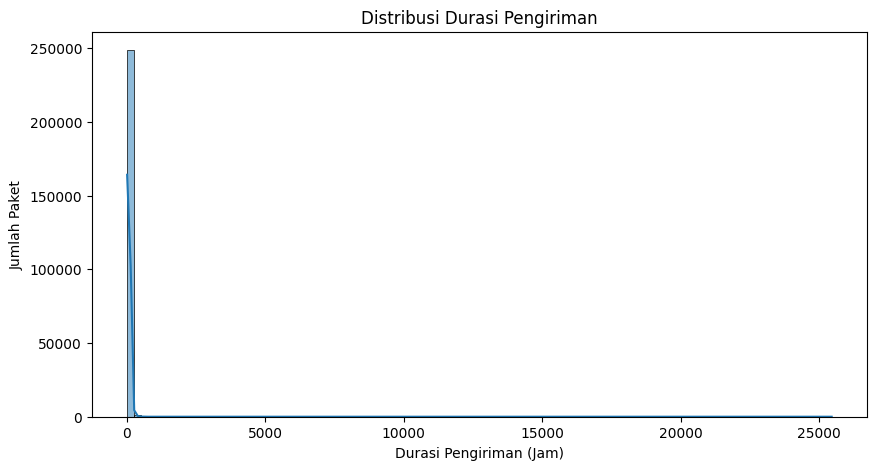

In [ ]:

print(
    df_train["durasi_jam"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50,
                     0.75, 0.90, 0.95, 0.99]
    )
)

plt.figure(figsize=(10, 5))

sns.histplot(
    df_train["durasi_jam"],
    bins=100,
    kde=True
)

plt.title("Distribusi Durasi Pengiriman")
plt.xlabel("Durasi Pengiriman (Jam)")
plt.ylabel("Jumlah Paket")
plt.show()


In [ ]:

# Mengubah kolom tanggal menjadi datetime
df_train["tgl_pickup"] = pd.to_datetime(
    df_train["tgl_pickup"]
)

df_test["tgl_pickup"] = pd.to_datetime(
    df_test["tgl_pickup"]
)

print(df_train["tgl_pickup"].dtype)
print(df_test["tgl_pickup"].dtype)


datetime64[ns]
datetime64[ns]


In [ ]:

# Training: Januari - Juni 2025
train_data = df_train[
    df_train["tgl_pickup"] < "2025-07-01"
].copy()

# Validation: Juli - Agustus 2025
valid_data = df_train[
    df_train["tgl_pickup"] >= "2025-07-01"
].copy()

print("Jumlah Training:", len(train_data))
print("Jumlah Validation:", len(valid_data))

print(
    "Tanggal Training:",
    train_data["tgl_pickup"].min(),
    "-",
    train_data["tgl_pickup"].max()
)

print(
    "Tanggal Validation:",
    valid_data["tgl_pickup"].min(),
    "-",
    valid_data["tgl_pickup"].max()
)


Jumlah Training: 181396
Jumlah Validation: 68604
Tanggal Training: 2025-01-01 00:00:00 - 2025-06-30 00:00:00
Tanggal Validation: 2025-07-01 00:00:00 - 2025-08-31 00:00:00


In [ ]:

# Kolom kategorikal, tanpa ID dan tanggal
categorical_cols = [
    "layanan",
    "mitra_kurir",
    "hub_asal",
    "kota_asal",
    "pulau_tujuan",
    "kota_tujuan"
]

for col in categorical_cols:

    train_categories = set(
        df_train[col].dropna().unique()
    )

    test_categories = set(
        df_test[col].dropna().unique()
    )

    new_categories = test_categories - train_categories

    print(f"\nKolom: {col}")
    print("Jumlah kategori training:", len(train_categories))
    print("Jumlah kategori testing:", len(test_categories))
    print("Kategori baru:", new_categories)
    print("Jumlah kategori baru:", len(new_categories))



Kolom: layanan
Jumlah kategori training: 4
Jumlah kategori testing: 4
Kategori baru: set()
Jumlah kategori baru: 0

Kolom: mitra_kurir
Jumlah kategori training: 12
Jumlah kategori testing: 13
Kategori baru: {'K13'}
Jumlah kategori baru: 1

Kolom: hub_asal
Jumlah kategori training: 6
Jumlah kategori testing: 6
Kategori baru: set()
Jumlah kategori baru: 0

Kolom: kota_asal
Jumlah kategori training: 30
Jumlah kategori testing: 30
Kategori baru: set()
Jumlah kategori baru: 0

Kolom: pulau_tujuan
Jumlah kategori training: 7
Jumlah kategori testing: 7
Kategori baru: set()
Jumlah kategori baru: 0

Kolom: kota_tujuan
Jumlah kategori training: 405
Jumlah kategori testing: 405
Kategori baru: set()
Jumlah kategori baru: 0


In [ ]:
cardinality = pd.DataFrame({
    "Kolom": categorical_cols,
    "Jumlah Kategori": [
        df_train[col].nunique()
        for col in categorical_cols
    ]
})

display(
    cardinality.sort_values(
        by="Jumlah Kategori",
        ascending=False
    )
)

,Kolom,Jumlah Kategori
5,kota_tujuan,405
3,kota_asal,30
1,mitra_kurir,12
4,pulau_tujuan,7
2,hub_asal,6
0,layanan,4


In [ ]:
kolom_pemeriksaan = [
    "id_paket",
    "tgl_pickup",
    "layanan",
    "mitra_kurir",
    "kota_asal",
    "kota_tujuan",
    "jarak_km",
    "berat_kg",
    "jumlah_scan",
    "durasi_jam"
]

outlier_data = df_train.nlargest(
    20, "durasi_jam"
)[kolom_pemeriksaan]

display(outlier_data)

,id_paket,tgl_pickup,layanan,mitra_kurir,kota_asal,kota_tujuan,jarak_km,berat_kg,jumlah_scan,durasi_jam
84362,P40474529,2025-07-04,reguler,K02,KA18,KT020,648.4,1.49,52,25452.0
108275,P62729634,2025-02-06,ekspres,K03,KA01,KT063,188.1,0.28,55,25020.0
98789,P12077092,2025-03-03,hemat,K03,KA15,KT063,187.7,1.72,37,16650.0
142557,P97171338,2025-01-16,hemat,K12,KA15,KT391,3434.7,3.21,32,16284.0
62562,P34488358,2025-08-10,hemat,K02,KA29,KT247,1311.2,2.79,42,13914.0
63531,P51550495,2025-08-28,hemat,K01,KA30,KT066,1154.6,1.48,34,13812.0
207233,P30815212,2025-04-26,hemat,K03,KA19,KT063,229.6,1.41,23,13746.0
205666,P76218261,2025-06-23,kargo,K01,KA09,KT391,2579.8,6.68,29,13560.0
146636,P28725772,2025-07-26,hemat,K07,KA28,KT025,1590.7,0.96,21,13482.0
237355,P58123091,2025-08-13,hemat,K06,KA09,KT280,1294.2,0.58,22,12582.0


In [ ]:

batas_durasi = [168, 720, 2160, 8760]

for batas in batas_durasi:
    jumlah = (df_train["durasi_jam"] > batas).sum()
    persentase = jumlah / len(df_train) * 100

    print(f"Durasi > {batas} jam")
    print(f"Jumlah data: {jumlah}")
    print(f"Persentase: {persentase:.4f}%")
    print("-" * 35)


Durasi > 168 jam
Jumlah data: 7480
Persentase: 2.9920%
-----------------------------------
Durasi > 720 jam
Jumlah data: 370
Persentase: 0.1480%
-----------------------------------
Durasi > 2160 jam
Jumlah data: 327
Persentase: 0.1308%
-----------------------------------
Durasi > 8760 jam
Jumlah data: 22
Persentase: 0.0088%
-----------------------------------


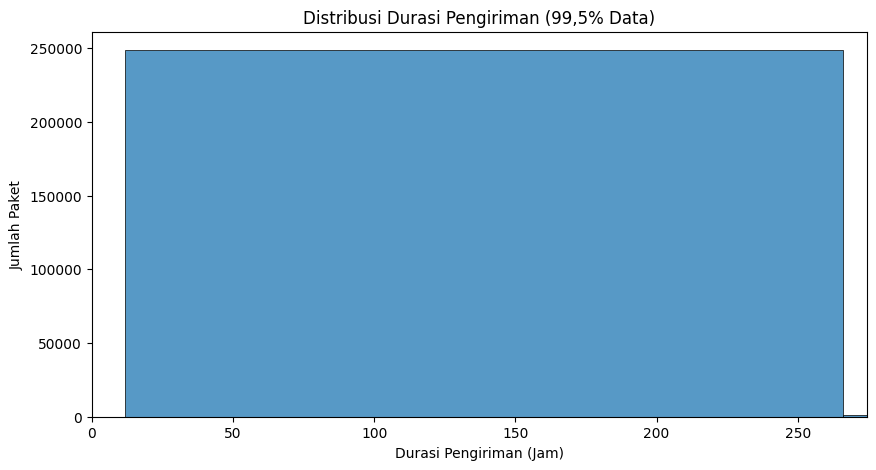

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    df_train["durasi_jam"],
    bins=100
)

plt.xlim(
    0,
    df_train["durasi_jam"].quantile(0.995)
)

plt.title("Distribusi Durasi Pengiriman (99,5% Data)")
plt.xlabel("Durasi Pengiriman (Jam)")
plt.ylabel("Jumlah Paket")
plt.show()


In [ ]:

persentil = df_train["durasi_jam"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
)

display(
    persentil.rename("Durasi (Jam)").to_frame()
)


,Durasi (Jam)
0.500,61.7000
0.750,85.3000
0.900,117.8000
0.950,145.8000
0.990,224.7010
0.995,274.5005
0.999,3054.0180


In [ ]:

for col in categorical_cols:

    kategori_train = set(
        train_data[col].dropna().unique()
    )

    kategori_valid = set(
        valid_data[col].dropna().unique()
    )

    kategori_baru = kategori_valid - kategori_train

    print(f"\nKolom: {col}")
    print("Kategori baru pada validation:", kategori_baru)
    print("Jumlah kategori baru:", len(kategori_baru))



Kolom: layanan
Kategori baru pada validation: set()
Jumlah kategori baru: 0

Kolom: mitra_kurir
Kategori baru pada validation: set()
Jumlah kategori baru: 0

Kolom: hub_asal
Kategori baru pada validation: set()
Jumlah kategori baru: 0

Kolom: kota_asal
Kategori baru pada validation: set()
Jumlah kategori baru: 0

Kolom: pulau_tujuan
Kategori baru pada validation: set()
Jumlah kategori baru: 0

Kolom: kota_tujuan
Kategori baru pada validation: set()
Jumlah kategori baru: 0


In [ ]:

kamus_path = os.path.join(
    extract_path, "kamus_data.md"
)

with open(kamus_path, "r", encoding="utf-8") as file:
    kamus = file.read()

kata_kunci = [
    "jumlah_scan",
    "pickup",
    "durasi_jam",
    "f01",
    "f50",
    "berat_kg",
    "hujan_asal_mm",
    "hujan_tujuan_mm"
]

for kata in kata_kunci:
    print("\n" + "=" * 60)
    print("PENCARIAN:", kata)

    for baris in kamus.splitlines():
        if kata.lower() in baris.lower():
            print(baris)



PENCARIAN: jumlah_scan
| jumlah_scan | Jumlah scan pelacakan yang tercatat di sistem |

PENCARIAN: pickup
| tgl_pickup, jam_pickup | Tanggal dan jam paket diambil kurir |

PENCARIAN: durasi_jam
| durasi_jam | Label: jam dari pengambilan sampai paket diterima. Hanya di data latih |

PENCARIAN: f01
| f01-f50 | Fitur internal sistem logistik (anonim), dihitung saat paket diambil |

PENCARIAN: f50
| f01-f50 | Fitur internal sistem logistik (anonim), dihitung saat paket diambil |

PENCARIAN: berat_kg
| berat_kg | Berat yang dideklarasikan penjual (kg) |

PENCARIAN: hujan_asal_mm
| hujan_asal_mm, hujan_tujuan_mm | Prakiraan curah hujan hari itu (mm) |

PENCARIAN: hujan_tujuan_mm
| hujan_asal_mm, hujan_tujuan_mm | Prakiraan curah hujan hari itu (mm) |


In [ ]:

df_train["bulan"] = df_train["tgl_pickup"].dt.month

analisis_bulanan = df_train.groupby("bulan").agg(
    jumlah_paket=("durasi_jam", "count"),
    median_durasi=("durasi_jam", "median"),
    rata_rata=("durasi_jam", "mean"),
    p90=("durasi_jam", lambda x: x.quantile(0.90)),
    maksimum=("durasi_jam", "max")
)

display(analisis_bulanan)


,jumlah_paket,median_durasi,rata_rata,p90,maksimum
bulan,,,,,
1,29985,59.6,75.348911,112.56,16284.0
2,27556,59.1,75.541407,111.70,25020.0
3,32829,67.5,82.160340,123.92,16650.0
4,26244,60.4,75.974242,118.60,13746.0
5,32841,61.5,77.033842,119.10,10656.0
6,31941,59.6,75.273802,112.90,13560.0
7,34436,62.9,80.714528,122.10,25452.0
8,34168,61.9,79.425439,118.00,13914.0


In [ ]:


print("DISTRIBUSI JUMLAH SCAN TRAINING")
print(df_train["jumlah_scan"].value_counts().sort_index())

print("\nSTATISTIK JUMLAH SCAN TRAINING")
display(df_train["jumlah_scan"].describe())

print("\nDISTRIBUSI JUMLAH SCAN TESTING")
print(df_test["jumlah_scan"].value_counts().sort_index())

print("\nKORELASI DENGAN TARGET")
print(
    df_train[["jumlah_scan", "durasi_jam"]]
    .corr()
)



DISTRIBUSI JUMLAH SCAN TRAINING
jumlah_scan
1      1359
2      5192
3     10845
4     16529
5     20972
      ...  
72        1
73        1
75        1
77        2
97        1
Name: count, Length: 76, dtype: int64

STATISTIK JUMLAH SCAN TRAINING


,jumlah_scan
count,250000.000000
mean,9.651072
std,5.625028
min,1.000000
25%,6.000000
50%,8.000000
75%,12.000000
max,97.000000



DISTRIBUSI JUMLAH SCAN TESTING
jumlah_scan
1    36336
2    18223
3     4560
4      765
5      100
6       14
7        2
Name: count, dtype: int64

KORELASI DENGAN TARGET
             jumlah_scan  durasi_jam
jumlah_scan     1.000000    0.188725
durasi_jam      0.188725    1.000000


In [ ]:


def feature_engineering(df):
    df = df.copy()

    df["tgl_pickup"] = pd.to_datetime(df["tgl_pickup"])

    # Fitur waktu
    df["tahun"] = df["tgl_pickup"].dt.year
    df["bulan"] = df["tgl_pickup"].dt.month
    df["hari"] = df["tgl_pickup"].dt.day
    df["hari_dalam_minggu"] = df["tgl_pickup"].dt.dayofweek
    df["akhir_pekan"] = (
        df["hari_dalam_minggu"] >= 5
    ).astype(int)

    # Representasi tren waktu
    df["hari_sejak_awal"] = (
        df["tgl_pickup"] - pd.Timestamp("2025-01-01")
    ).dt.days

    # Menghapus kolom tanggal asli
    df = df.drop(columns=["tgl_pickup"])

    return df


train_fe = feature_engineering(df_train)
test_fe = feature_engineering(df_test)

print("Training:", train_fe.shape)
print("Testing:", test_fe.shape)

display(train_fe.head())



Training: (250000, 82)
Testing: (60000, 81)


,id_paket,jam_pickup,layanan,mitra_kurir,hub_asal,kota_asal,pulau_tujuan,kota_tujuan,jarak_km,berat_kg,...,f48,f49,f50,durasi_jam,bulan,tahun,hari,hari_dalam_minggu,akhir_pekan,hari_sejak_awal
0,P24198861,10,ekspres,K07,JKT,KA01,Jawa,KT099,1077.6,0.44,...,0.721,0.661,3.760,40.4,3,2025,13,3,0,71
1,P44313480,9,reguler,K05,SBY,KA09,Jawa,KT101,829.3,0.71,...,0.065,0.232,1.866,78.7,6,2025,24,1,0,174
2,P18332724,11,kargo,K03,JKT,KA02,Jawa,KT066,758.6,NaN,...,-1.031,0.777,2.809,101.3,5,2025,7,2,0,126
3,P85422083,14,ekspres,K03,MKS,KA28,Sulawesi,KT273,396.2,1.11,...,-1.766,0.275,1.498,60.3,5,2025,19,0,0,138
4,P60211760,7,kargo,K07,SMG,KA20,Jawa,KT066,254.6,NaN,...,-0.886,0.180,0.512,63.1,4,2025,29,1,0,118


In [ ]:

# Kolom yang tidak digunakan sebagai fitur
drop_cols = [
    "id_paket",
    "jumlah_scan",
    "durasi_jam"
]

# Memisahkan target
X_train = train_data.drop(
    columns=["id_paket", "jumlah_scan", "durasi_jam"]
)

y_train = train_data["durasi_jam"]

X_valid = valid_data.drop(
    columns=["id_paket", "jumlah_scan", "durasi_jam"]
)

y_valid = valid_data["durasi_jam"]

# Feature engineering pada fitur training dan validation
X_train = feature_engineering(X_train)
X_valid = feature_engineering(X_valid)

# Fitur kategorikal
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Memastikan kategori konsisten sebagai string
for col in categorical_features:
    X_train[col] = X_train[col].fillna("UNKNOWN").astype(str)
    X_valid[col] = X_valid[col].fillna("UNKNOWN").astype(str)

print("Jumlah fitur:", X_train.shape[1])
print("Fitur kategorikal:", categorical_features)
print("Missing value training:", X_train.isnull().sum().sum())
print("Missing value validation:", X_valid.isnull().sum().sum())


Jumlah fitur: 79
Fitur kategorikal: ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
Missing value training: 9990
Missing value validation: 3907


In [ ]:

!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 46.6 MB/s  0:00:02


In [ ]:

import catboost
from catboost import CatBoostRegressor

print("Versi CatBoost:", catboost.__version__)


Versi CatBoost: 1.2.10


In [ ]:

from sklearn.metrics import mean_pinball_loss, mean_absolute_error
import numpy as np
import pandas as pd

# Membuat prediksi baseline P50 dan P90
baseline_p50 = np.full(
    len(y_valid),
    y_train.quantile(0.50)
)

baseline_p90 = np.full(
    len(y_valid),
    y_train.quantile(0.90)
)

# Menghitung Pinball Loss
loss_p50 = mean_pinball_loss(
    y_valid,
    baseline_p50,
    alpha=0.50
)

loss_p90 = mean_pinball_loss(
    y_valid,
    baseline_p90,
    alpha=0.90
)

# Menghitung coverage P90
coverage_p90 = np.mean(y_valid <= baseline_p90)

# Menampilkan hasil
hasil_baseline = pd.DataFrame({
    "Metrik": [
        "Pinball Loss P50",
        "Pinball Loss P90",
        "Coverage P90",
        "Prediksi P50",
        "Prediksi P90"
    ],
    "Nilai": [
        loss_p50,
        loss_p90,
        coverage_p90,
        baseline_p50[0],
        baseline_p90[0]
    ]
})

display(hasil_baseline)


,Metrik,Nilai
0,Pinball Loss P50,17.396534
1,Pinball Loss P90,16.009844
2,Coverage P90,0.892033
3,Prediksi P50,61.400000
4,Prediksi P90,117.000000


In [ ]:

# Membuat model CatBoost untuk prediksi P50
model_p50 = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="Quantile:alpha=0.5",
    eval_metric="Quantile:alpha=0.5",
    random_seed=42,
    early_stopping_rounds=100,
    verbose=100
)

# Melatih model
model_p50.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_valid, y_valid),
    verbose=100
)

# Prediksi data validation
prediksi_p50 = model_p50.predict(X_valid)

# Evaluasi Pinball Loss P50
loss_catboost_p50 = mean_pinball_loss(
    y_valid,
    prediksi_p50,
    alpha=0.50
)

print("Pinball Loss CatBoost P50:", loss_catboost_p50)
print("Best iteration:", model_p50.best_iteration_)


0:	learn: 15.7767547	test: 17.0193758	best: 17.0193758 (0)	total: 1.69s	remaining: 28m 12s
100:	learn: 9.9074380	test: 11.0383634	best: 11.0383634 (100)	total: 1m 4s	remaining: 9m 35s
200:	learn: 9.5347653	test: 10.8247844	best: 10.8247844 (200)	total: 2m 7s	remaining: 8m 26s
300:	learn: 9.3985785	test: 10.7542913	best: 10.7542913 (300)	total: 3m 10s	remaining: 7m 23s
400:	learn: 9.3140161	test: 10.7181570	best: 10.7181570 (400)	total: 4m 15s	remaining: 6m 22s
500:	learn: 9.2540149	test: 10.7120547	best: 10.7120547 (500)	total: 5m 22s	remaining: 5m 21s
600:	learn: 9.2005418	test: 10.7059030	best: 10.7059030 (600)	total: 6m 27s	remaining: 4m 17s
700:	learn: 9.1488356	test: 10.6997915	best: 10.6997548 (699)	total: 7m 34s	remaining: 3m 13s
800:	learn: 9.1017088	test: 10.6976709	best: 10.6974352 (771)	total: 8m 40s	remaining: 2m 9s
900:	learn: 9.0589441	test: 10.6974789	best: 10.6965199 (813)	total: 9m 44s	remaining: 1m 4s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 

In [ ]:

# Membuat model CatBoost untuk prediksi P90
model_p90 = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="Quantile:alpha=0.9",
    eval_metric="Quantile:alpha=0.9",
    random_seed=42,
    early_stopping_rounds=100,
    verbose=100
)

# Melatih model
model_p90.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_valid, y_valid),
    verbose=100
)

# Prediksi data validation
prediksi_p90 = model_p90.predict(X_valid)

# Evaluasi Pinball Loss P90
loss_catboost_p90 = mean_pinball_loss(
    y_valid,
    prediksi_p90,
    alpha=0.90
)

# Menghitung coverage P90
coverage_catboost_p90 = np.mean(
    y_valid <= prediksi_p90
)

print("Pinball Loss CatBoost P90:", loss_catboost_p90)
print("Coverage CatBoost P90:", coverage_catboost_p90)
print("Best iteration:", model_p90.best_iteration_)


0:	learn: 13.8989599	test: 15.6400535	best: 15.6400535 (0)	total: 620ms	remaining: 10m 19s
100:	learn: 9.5901687	test: 11.3937097	best: 11.3926253 (99)	total: 58.4s	remaining: 8m 39s
200:	learn: 9.4253987	test: 11.3389161	best: 11.3380352 (188)	total: 2m	remaining: 7m 57s
300:	learn: 9.3197526	test: 11.3458548	best: 11.3339127 (256)	total: 3m 3s	remaining: 7m 6s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 11.33391271
bestIteration = 256

Shrink model to first 257 iterations.
Pinball Loss CatBoost P90: 11.333912918355631
Coverage CatBoost P90: 0.8676024721590578
Best iteration: 256


In [ ]:

# Menggabungkan hasil prediksi P50 dan P90
hasil_prediksi = pd.DataFrame({
    "durasi_aktual": y_valid.values,
    "prediksi_p50": prediksi_p50,
    "prediksi_p90": prediksi_p90
})

# Memeriksa apakah terjadi quantile crossing
jumlah_crossing = (
    hasil_prediksi["prediksi_p90"] <
    hasil_prediksi["prediksi_p50"]
).sum()

persentase_crossing = (
    jumlah_crossing / len(hasil_prediksi)
) * 100

print("Jumlah prediksi P90 < P50:", jumlah_crossing)
print("Persentase quantile crossing:", persentase_crossing, "%")

# Statistik hasil prediksi
display(
    hasil_prediksi[
        ["durasi_aktual", "prediksi_p50", "prediksi_p90"]
    ].describe().round(2)
)


Jumlah prediksi P90 < P50: 4
Persentase quantile crossing: 0.005830563815520961 %


,durasi_aktual,prediksi_p50,prediksi_p90
count,68604.00,68604.00,68604.00
mean,80.07,67.33,90.99
std,244.99,30.84,44.50
min,13.10,11.64,14.83
25%,46.10,46.36,62.42
50%,62.40,60.09,80.23
75%,86.80,80.34,106.37
max,25452.00,312.44,1316.53


In [ ]:

# Salin prediksi agar hasil model asli tetap tersimpan
prediksi_p90_terkoreksi = prediksi_p90.copy()

# Memperbaiki quantile crossing
mask_crossing = prediksi_p90_terkoreksi < prediksi_p50

prediksi_p90_terkoreksi[mask_crossing] = (
    prediksi_p50[mask_crossing]
)

print(
    "Jumlah quantile crossing setelah koreksi:",
    np.sum(prediksi_p90_terkoreksi < prediksi_p50)
)

# Evaluasi ulang P90 setelah koreksi
loss_p90_koreksi = mean_pinball_loss(
    y_valid,
    prediksi_p90_terkoreksi,
    alpha=0.90
)

coverage_p90_koreksi = np.mean(
    y_valid <= prediksi_p90_terkoreksi
)

print("Pinball Loss P90 setelah koreksi:", loss_p90_koreksi)
print("Coverage P90 setelah koreksi:", coverage_p90_koreksi)


Jumlah quantile crossing setelah koreksi: 0
Pinball Loss P90 setelah koreksi: 11.33413582349624
Coverage P90 setelah koreksi: 0.8676024721590578


In [ ]:

# Mengambil tanggal dari data validation
tanggal_valid = pd.to_datetime(
    valid_data["tgl_pickup"]
)

# Memisahkan indeks data Juli dan Agustus
mask_juli = (
    (tanggal_valid.dt.year == 2025) &
    (tanggal_valid.dt.month == 7)
)

mask_agustus = (
    (tanggal_valid.dt.year == 2025) &
    (tanggal_valid.dt.month == 8)
)

# Memisahkan target aktual
y_juli = y_valid[mask_juli]
y_agustus = y_valid[mask_agustus]

# Memisahkan prediksi P90
p90_juli = prediksi_p90_terkoreksi[mask_juli]
p90_agustus = prediksi_p90_terkoreksi[mask_agustus]

print("Jumlah data Juli:", len(y_juli))
print("Jumlah data Agustus:", len(y_agustus))

print("Rentang Juli:",
      tanggal_valid[mask_juli].min(),
      "sampai",
      tanggal_valid[mask_juli].max())

print("Rentang Agustus:",
      tanggal_valid[mask_agustus].min(),
      "sampai",
      tanggal_valid[mask_agustus].max())


Jumlah data Juli: 34436
Jumlah data Agustus: 34168
Rentang Juli: 2025-07-01 00:00:00 sampai 2025-07-31 00:00:00
Rentang Agustus: 2025-08-01 00:00:00 sampai 2025-08-31 00:00:00


In [ ]:

# 1. Menghitung residual pada data Juli
residual_juli = y_juli.values - p90_juli

# 2. Menghitung kuantil residual dengan koreksi finite-sample
n_cal = len(residual_juli)

alpha = 0.10
rank = int(np.ceil((n_cal + 1) * (1 - alpha)))

delta_p90 = np.sort(residual_juli)[rank - 1]

print("Jumlah data kalibrasi:", n_cal)
print("Peringkat residual:", rank)
print("Penyesuaian P90:", delta_p90, "jam")

# 3. Menerapkan kalibrasi pada data Agustus
p90_agustus_kalibrasi = p90_agustus + delta_p90

# Memastikan P90 tidak lebih kecil daripada P50
p50_agustus = prediksi_p50[mask_agustus]

p90_agustus_kalibrasi = np.maximum(
    p90_agustus_kalibrasi,
    p50_agustus
)

# 4. Menghitung performa sebelum dan sesudah kalibrasi
coverage_sebelum = np.mean(
    y_agustus.values <= p90_agustus
)

coverage_sesudah = np.mean(
    y_agustus.values <= p90_agustus_kalibrasi
)

loss_sebelum = mean_pinball_loss(
    y_agustus,
    p90_agustus,
    alpha=0.90
)

loss_sesudah = mean_pinball_loss(
    y_agustus,
    p90_agustus_kalibrasi,
    alpha=0.90
)

# 5. Membandingkan hasil
hasil_kalibrasi = pd.DataFrame({
    "Metrik": [
        "Coverage P90",
        "Pinball Loss P90",
        "Rata-rata Prediksi P90"
    ],
    "Sebelum Kalibrasi": [
        coverage_sebelum,
        loss_sebelum,
        np.mean(p90_agustus)
    ],
    "Sesudah Kalibrasi": [
        coverage_sesudah,
        loss_sesudah,
        np.mean(p90_agustus_kalibrasi)
    ]
})

display(hasil_kalibrasi.round(4))


Jumlah data kalibrasi: 34436
Peringkat residual: 30994
Penyesuaian P90: 4.992466301847685 jam


,Metrik,Sebelum Kalibrasi,Sesudah Kalibrasi
0,Coverage P90,0.8720,0.9078
1,Pinball Loss P90,11.4071,11.3614
2,Rata-rata Prediksi P90,90.5319,95.5243


In [ ]:

!pip install lightgbm


In [ ]:

import lightgbm as lgb
from lightgbm import LGBMRegressor

print("Versi LightGBM:", lgb.__version__)


Versi LightGBM: 4.6.0


In [ ]:

# Membuat salinan data agar data CatBoost tetap aman
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()

# Mengubah fitur kategorikal menjadi pandas category
for col in categorical_features:

    # Menyamakan daftar kategori training dan validation
    kategori = pd.Index(
        pd.concat([
            X_train_lgb[col],
            X_valid_lgb[col]
        ]).unique()
    )

    X_train_lgb[col] = pd.Categorical(
        X_train_lgb[col],
        categories=kategori
    )

    X_valid_lgb[col] = pd.Categorical(
        X_valid_lgb[col],
        categories=kategori
    )

print("Fitur kategorikal LightGBM:")
print(X_train_lgb[categorical_features].dtypes)

print("\nJumlah fitur:", X_train_lgb.shape[1])
print("Missing value training:", X_train_lgb.isnull().sum().sum())
print("Missing value validation:", X_valid_lgb.isnull().sum().sum())


Fitur kategorikal LightGBM:
layanan         category
mitra_kurir     category
hub_asal        category
kota_asal       category
pulau_tujuan    category
kota_tujuan     category
dtype: object

Jumlah fitur: 79
Missing value training: 9990
Missing value validation: 3907


In [ ]:

# Membuat model LightGBM untuk prediksi P50
model_lgb_p50 = LGBMRegressor(
    objective="quantile",
    alpha=0.5,
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Melatih model
model_lgb_p50.fit(
    X_train_lgb,
    y_train,
    categorical_feature=categorical_features,
    eval_set=[(X_valid_lgb, y_valid)],
    eval_metric="quantile",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100,
            verbose=True
        ),
        lgb.log_evaluation(100)
    ]
)

# Prediksi data validation
prediksi_lgb_p50 = model_lgb_p50.predict(
    X_valid_lgb
)

# Evaluasi Pinball Loss P50
loss_lgb_p50 = mean_pinball_loss(
    y_valid,
    prediksi_lgb_p50,
    alpha=0.50
)

print("\nPinball Loss LightGBM P50:", loss_lgb_p50)
print("Best iteration:", model_lgb_p50.best_iteration_)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's quantile: 11.1124
[200]	valid_0's quantile: 10.8949
[300]	valid_0's quantile: 10.8258
[400]	valid_0's quantile: 10.8026
[500]	valid_0's quantile: 10.7928
[600]	valid_0's quantile: 10.7886
[700]	valid_0's quantile: 10.7839
[800]	valid_0's quantile: 10.7783
[900]	valid_0's quantile: 10.7726
[1000]	valid_0's quantile: 10.7735
Did not meet early stopping. Best iteration is:
[929]	valid_0's quantile: 10.7721

Pinball Loss LightGBM P50: 10.77205229104649
Best iteration: 929


In [ ]:

# Membuat model LightGBM untuk prediksi P90
model_lgb_p90 = LGBMRegressor(
    objective="quantile",
    alpha=0.9,
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Melatih model
model_lgb_p90.fit(
    X_train_lgb,
    y_train,
    categorical_feature=categorical_features,
    eval_set=[(X_valid_lgb, y_valid)],
    eval_metric="quantile",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100,
            verbose=True
        ),
        lgb.log_evaluation(100)
    ]
)

# Prediksi data validation
prediksi_lgb_p90 = model_lgb_p90.predict(
    X_valid_lgb
)

# Evaluasi Pinball Loss P90
loss_lgb_p90 = mean_pinball_loss(
    y_valid,
    prediksi_lgb_p90,
    alpha=0.90
)

# Menghitung coverage P90
coverage_lgb_p90 = np.mean(
    y_valid.values <= prediksi_lgb_p90
)

print("\nPinball Loss LightGBM P90:", loss_lgb_p90)
print("Coverage LightGBM P90:", coverage_lgb_p90)
print("Best iteration:", model_lgb_p90.best_iteration_)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's quantile: 11.473
[200]	valid_0's quantile: 11.4294
Early stopping, best iteration is:
[187]	valid_0's quantile: 11.4274

Pinball Loss LightGBM P90: 11.427425257951745
Coverage LightGBM P90: 0.8643082036032884
Best iteration: 187


In [ ]:

# Membuat tabel perbandingan seluruh model
perbandingan_model = pd.DataFrame({
    "Model": [
        "Baseline",
        "CatBoost",
        "LightGBM"
    ],
    "Pinball Loss P50": [
        loss_p50,
        loss_catboost_p50,
        loss_lgb_p50
    ],
    "Pinball Loss P90": [
        loss_p90,
        loss_catboost_p90,
        loss_lgb_p90
    ],
    "Coverage P90 (%)": [
        coverage_p90 * 100,
        coverage_catboost_p90 * 100,
        coverage_lgb_p90 * 100
    ]
})

display(perbandingan_model.round(4))


,Model,Pinball Loss P50,Pinball Loss P90,Coverage P90 (%)
0,Baseline,17.3965,16.0098,89.2033
1,CatBoost,10.6965,11.3339,86.7602
2,LightGBM,10.7721,11.4274,86.4308


In [ ]:
# 1. Memastikan prediksi P90 tidak lebih kecil dari P50
prediksi_lgb_p90_terkoreksi = np.maximum(
    prediksi_lgb_p90,
    prediksi_lgb_p50
)

# 2. Mengambil prediksi dan target bulan Juli
y_juli_lgb = y_valid[mask_juli].values

p90_juli_lgb = prediksi_lgb_p90_terkoreksi[mask_juli]

# 3. Menghitung residual bulan Juli
residual_juli_lgb = y_juli_lgb - p90_juli_lgb

# 4. Menghitung nilai koreksi P90
n_cal_lgb = len(residual_juli_lgb)
alpha = 0.10

rank_lgb = int(np.ceil((n_cal_lgb + 1) * (1 - alpha)))

delta_p90_lgb = np.sort(residual_juli_lgb)[rank_lgb - 1]

# 5. Mengambil prediksi bulan Agustus
y_agustus_lgb = y_valid[mask_agustus].values

p90_agustus_lgb = prediksi_lgb_p90_terkoreksi[mask_agustus]

p50_agustus_lgb = prediksi_lgb_p50[mask_agustus]

# 6. Menghitung prediksi P90 sebelum kalibrasi
coverage_sebelum_lgb = np.mean(
    y_agustus_lgb <= p90_agustus_lgb
)

loss_sebelum_lgb = mean_pinball_loss(
    y_agustus_lgb,
    p90_agustus_lgb,
    alpha=0.9
)

# 7. Menerapkan kalibrasi
p90_agustus_lgb_kalibrasi = p90_agustus_lgb + delta_p90_lgb

# Memastikan P90 tidak lebih kecil dari P50
p90_agustus_lgb_kalibrasi = np.maximum(
    p90_agustus_lgb_kalibrasi,
    p50_agustus_lgb
)

# 8. Menghitung hasil setelah kalibrasi
coverage_setelah_lgb = np.mean(
    y_agustus_lgb <= p90_agustus_lgb_kalibrasi
)

loss_setelah_lgb = mean_pinball_loss(
    y_agustus_lgb,
    p90_agustus_lgb_kalibrasi,
    alpha=0.9
)

# 9. Menampilkan hasil
print("HASIL KALIBRASI P90 LIGHTGBM")
print("Jumlah data kalibrasi:", n_cal_lgb)
print("Nilai rank:", rank_lgb)
print("Delta P90:", delta_p90_lgb)

print("\nSEBELUM KALIBRASI")
print("Coverage P90:", round(coverage_sebelum_lgb * 100, 4), "%")
print("Pinball Loss P90:", round(loss_sebelum_lgb, 4))

print("\nSETELAH KALIBRASI")
print("Coverage P90:", round(coverage_setelah_lgb * 100, 4), "%")
print("Pinball Loss P90:", round(loss_setelah_lgb, 4))

HASIL KALIBRASI P90 LIGHTGBM
Jumlah data kalibrasi: 34436
Nilai rank: 30994
Delta P90: 5.6627078246963265

SEBELUM KALIBRASI
Coverage P90: 86.9995 %
Pinball Loss P90: 11.4704

SETELAH KALIBRASI
Coverage P90: 90.9067 %
Pinball Loss P90: 11.4158


In [ ]:
# Menggabungkan data validasi dengan hasil prediksi CatBoost
hasil_analisis = valid_data.copy()

hasil_analisis["prediksi_p50"] = prediksi_p50
hasil_analisis["prediksi_p90"] = prediksi_p90_terkoreksi

# Menghitung error absolut P50
hasil_analisis["error_absolut_p50"] = np.abs(
    hasil_analisis["durasi_jam"] -
    hasil_analisis["prediksi_p50"]
)

# Menghitung apakah durasi aktual berada di bawah P90
hasil_analisis["tercakup_p90"] = (
    hasil_analisis["durasi_jam"] <=
    hasil_analisis["prediksi_p90"]
).astype(int)

print("JUMLAH DATA HASIL ANALISIS:", len(hasil_analisis))
display(hasil_analisis.head())

JUMLAH DATA HASIL ANALISIS: 68604


,id_paket,tgl_pickup,jam_pickup,layanan,mitra_kurir,hub_asal,kota_asal,pulau_tujuan,kota_tujuan,jarak_km,...,f46,f47,f48,f49,f50,durasi_jam,prediksi_p50,prediksi_p90,error_absolut_p50,tercakup_p90
14,P36381185,2025-07-22,9,ekspres,K01,SBY,KA12,Jawa,KT002,176.9,...,1.0,1.206,-0.250,0.599,1.732,32.4,31.878849,50.083099,0.521151,1
15,P66438338,2025-08-17,10,hemat,K03,SMG,KA20,Jawa,KT066,254.6,...,4.0,-1.249,-1.243,0.087,0.864,55.6,57.976410,76.594707,2.376410,1
16,P55081190,2025-08-15,18,hemat,K01,JKT,KA01,Jawa,KT066,741.6,...,2.0,0.760,0.231,0.150,3.420,58.9,64.484624,85.116231,5.584624,1
17,P10010533,2025-07-25,14,reguler,K03,BDG,KA15,Jawa,KT066,613.5,...,7.0,-1.884,-0.098,0.827,0.768,47.0,54.214027,66.828492,7.214027,1
22,P64747358,2025-08-08,7,reguler,K04,SBY,KA12,Sulawesi,KT271,1663.5,...,4.0,1.306,-1.632,0.970,0.679,94.8,93.816072,128.579039,0.983928,1


In [ ]:
# Fungsi untuk menghitung Pinball Loss
def hitung_pinball(y_aktual, y_prediksi, alpha):
    return mean_pinball_loss(
        y_aktual,
        y_prediksi,
        alpha=alpha
    )

# Mengelompokkan data berdasarkan layanan
hasil_layanan = hasil_analisis.groupby("layanan").apply(
    lambda df: pd.Series({
        "jumlah_data": len(df),

        "MAE_P50": df["error_absolut_p50"].mean(),

        "Pinball_Loss_P50": hitung_pinball(
            df["durasi_jam"],
            df["prediksi_p50"],
            0.5
        ),

        "Pinball_Loss_P90": hitung_pinball(
            df["durasi_jam"],
            df["prediksi_p90"],
            0.9
        ),

        "Coverage_P90": df["tercakup_p90"].mean() * 100
    })
).reset_index()

# Mengurutkan berdasarkan MAE P50
hasil_layanan = hasil_layanan.sort_values(
    "MAE_P50",
    ascending=True
)

display(hasil_layanan.round(4))

/tmp/ipykernel_3813/2469464247.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hasil_layanan = hasil_analisis.groupby("layanan").apply(


,layanan,jumlah_data,MAE_P50,Pinball_Loss_P50,Pinball_Loss_P90,Coverage_P90
0,ekspres,10106.0,10.7984,5.3992,5.0951,87.2056
3,reguler,28871.0,20.0781,10.0391,11.3461,86.6648
2,kargo,6867.0,21.1489,10.5745,9.9091,87.1123
1,hemat,22760.0,27.8389,13.9195,14.5192,86.5773


In [ ]:
print("Jumlah data layanan hemat:")
print(
    hasil_analisis[
        hasil_analisis["layanan"] == "hemat"
    ].shape[0]
)

print("\nDistribusi tercakup_p90 layanan hemat:")
print(
    hasil_analisis.loc[
        hasil_analisis["layanan"] == "hemat",
        "tercakup_p90"
    ].value_counts(dropna=False)
)

print("\nCoverage P90 layanan hemat:")
print(
    hasil_analisis.loc[
        hasil_analisis["layanan"] == "hemat",
        "tercakup_p90"
    ].mean() * 100
)

Jumlah data layanan hemat:
22760

Distribusi tercakup_p90 layanan hemat:
tercakup_p90
1    19705
0     3055
Name: count, dtype: int64

Coverage P90 layanan hemat:
86.57732864674868


In [ ]:
hasil_pulau = hasil_analisis.groupby("pulau_tujuan").agg(
    jumlah_data=("durasi_jam", "count"),
    MAE_P50=("error_absolut_p50", "mean"),
    Coverage_P90=("tercakup_p90", "mean")
).reset_index()

# Menghitung Pinball Loss untuk setiap pulau
pinball_p50 = hasil_analisis.groupby("pulau_tujuan").apply(
    lambda df: mean_pinball_loss(
        df["durasi_jam"],
        df["prediksi_p50"],
        alpha=0.5
    )
)

pinball_p90 = hasil_analisis.groupby("pulau_tujuan").apply(
    lambda df: mean_pinball_loss(
        df["durasi_jam"],
        df["prediksi_p90"],
        alpha=0.9
    )
)

hasil_pulau["Pinball_Loss_P50"] = hasil_pulau["pulau_tujuan"].map(pinball_p50)
hasil_pulau["Pinball_Loss_P90"] = hasil_pulau["pulau_tujuan"].map(pinball_p90)

hasil_pulau["Coverage_P90"] *= 100

hasil_pulau = hasil_pulau.sort_values(
    "MAE_P50",
    ascending=True
)

display(hasil_pulau.round(4))

/tmp/ipykernel_3813/3948910235.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pinball_p50 = hasil_analisis.groupby("pulau_tujuan").apply(
/tmp/ipykernel_3813/3948910235.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pinball_p90 = hasil_analisis.groupby("pulau_tujuan").apply(


,pulau_tujuan,jumlah_data,MAE_P50,Coverage_P90,Pinball_Loss_P50,Pinball_Loss_P90
1,Jawa,45800,16.6139,86.4127,8.3070,9.0224
6,Sumatera,9178,19.7658,87.6879,9.8829,9.1602
0,Bali-Nusa Tenggara,2659,19.8480,87.8902,9.9240,8.2411
2,Kalimantan,3868,39.3428,87.4612,19.6714,21.7250
5,Sulawesi,4532,43.1560,86.6505,21.5780,25.7563
3,Maluku,1341,45.0647,89.6346,22.5324,23.3439
4,Papua,1226,52.4892,85.3997,26.2446,21.4450


In [ ]:
data_papua = hasil_analisis[
    hasil_analisis["pulau_tujuan"] == "Papua"
]

loss_p90_papua = mean_pinball_loss(
    data_papua["durasi_jam"],
    data_papua["prediksi_p90"],
    alpha=0.9
)

print("Jumlah data Papua:", len(data_papua))
print("Pinball Loss P90 Papua:", round(loss_p90_papua, 4))

Jumlah data Papua: 1226
Pinball Loss P90 Papua: 21.445


In [ ]:
# Mengelompokkan data berdasarkan mitra kurir
hasil_mitra = hasil_analisis.groupby("mitra_kurir").agg(
    jumlah_data=("durasi_jam", "count"),
    MAE_P50=("error_absolut_p50", "mean"),
    Coverage_P90=("tercakup_p90", "mean")
).reset_index()

# Menghitung Pinball Loss P50 dan P90
pinball_mitra_p50 = hasil_analisis.groupby("mitra_kurir").apply(
    lambda df: mean_pinball_loss(
        df["durasi_jam"],
        df["prediksi_p50"],
        alpha=0.5
    )
)

pinball_mitra_p90 = hasil_analisis.groupby("mitra_kurir").apply(
    lambda df: mean_pinball_loss(
        df["durasi_jam"],
        df["prediksi_p90"],
        alpha=0.9
    )
)

hasil_mitra["Pinball_Loss_P50"] = (
    hasil_mitra["mitra_kurir"].map(pinball_mitra_p50)
)

hasil_mitra["Pinball_Loss_P90"] = (
    hasil_mitra["mitra_kurir"].map(pinball_mitra_p90)
)

hasil_mitra["Coverage_P90"] *= 100

# Mengurutkan berdasarkan MAE P50
hasil_mitra = hasil_mitra.sort_values(
    "MAE_P50",
    ascending=True
)

display(hasil_mitra.round(4))

/tmp/ipykernel_3813/1046060654.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pinball_mitra_p50 = hasil_analisis.groupby("mitra_kurir").apply(
/tmp/ipykernel_3813/1046060654.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pinball_mitra_p90 = hasil_analisis.groupby("mitra_kurir").apply(


,mitra_kurir,jumlah_data,MAE_P50,Coverage_P90,Pinball_Loss_P50,Pinball_Loss_P90
10,K11,3392,13.5652,90.1828,6.7826,4.8440
11,K12,2808,14.5244,88.8177,7.2622,5.4076
4,K05,6197,16.2937,89.3497,8.1469,7.1969
8,K09,4072,16.8523,88.1139,8.4261,8.2701
7,K08,4777,17.8536,89.7216,8.9268,9.6445
9,K10,4179,18.4853,89.2558,9.2427,8.8694
3,K04,6777,19.4637,90.4382,9.7318,10.3041
2,K03,7621,19.7278,89.4502,9.8639,9.8561
0,K01,9621,22.5760,89.3254,11.2880,13.2943
1,K02,8309,24.7811,88.7231,12.3906,14.3496


In [ ]:
data_k07 = hasil_analisis[
    hasil_analisis["mitra_kurir"] == "K07"
]

loss_p90_k07 = mean_pinball_loss(
    data_k07["durasi_jam"],
    data_k07["prediksi_p90"],
    alpha=0.9
)

print("Jumlah data K07:", len(data_k07))
print("Pinball Loss P90 K07:", round(loss_p90_k07, 4))

Jumlah data K07: 5448
Pinball Loss P90 K07: 17.8073


In [ ]:
from catboost import Pool

# Mengambil sampel data validasi
X_shap = X_valid.sample(
    n=2000,
    random_state=42
)

y_shap = y_valid.loc[X_shap.index]

# Membuat Pool untuk CatBoost
data_shap = Pool(
    data=X_shap,
    label=y_shap,
    cat_features=categorical_features
)

# Menghitung nilai SHAP
shap_values = model_p50.get_feature_importance(
    data=data_shap,
    type="ShapValues"
)

# Menghilangkan kolom terakhir (expected value)
nilai_shap = shap_values[:, :-1]

print("Jumlah data sampel:", len(X_shap))
print("Jumlah fitur:", len(X_shap.columns))
print("Bentuk matriks SHAP:", nilai_shap.shape)

Jumlah data sampel: 2000
Jumlah fitur: 79
Bentuk matriks SHAP: (2000, 79)


In [ ]:
# Menghitung rata-rata nilai absolut SHAP
importance_shap = pd.DataFrame({
    "fitur": X_shap.columns,
    "mean_abs_shap": np.abs(nilai_shap).mean(axis=0)
})

# Mengurutkan fitur dari pengaruh terbesar
importance_shap = importance_shap.sort_values(
    "mean_abs_shap",
    ascending=False
)

# Menampilkan 20 fitur teratas
display(importance_shap.head(20).round(4))

,fitur,mean_abs_shap
1,layanan,9.4730
3,hub_asal,4.4774
6,kota_tujuan,3.8691
5,pulau_tujuan,3.6724
39,f17,3.5282
7,jarak_km,2.8007
2,mitra_kurir,2.7638
19,antrean_hub_asal,2.6776
26,f04,2.0899
13,cod,1.8829


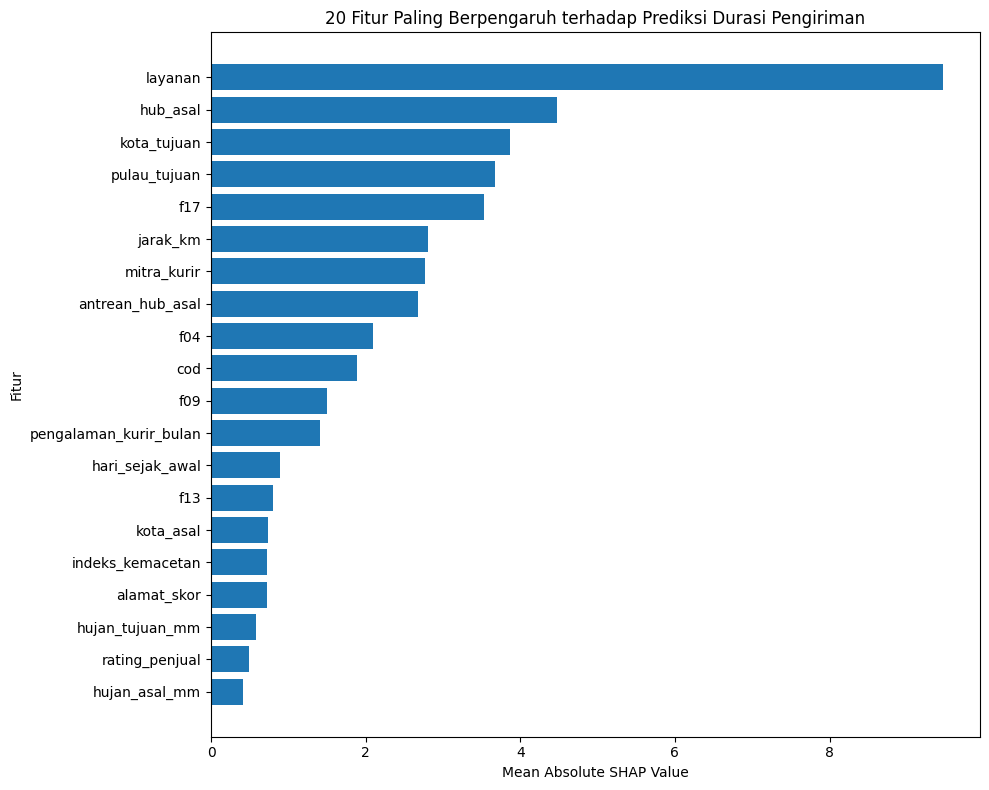

In [ ]:
import matplotlib.pyplot as plt

# Mengambil 20 fitur teratas
top_shap = importance_shap.head(20).sort_values(
    "mean_abs_shap",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_shap["fitur"],
    top_shap["mean_abs_shap"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Fitur")
plt.title("20 Fitur Paling Berpengaruh terhadap Prediksi Durasi Pengiriman")

plt.tight_layout()
plt.show()

In [ ]:
fitur_pdp = [
    "jarak_km",
    "antrean_hub_asal",
    "indeks_kemacetan"
]

print("Statistik fitur untuk PDP:")

display(
    X_valid[fitur_pdp].describe().round(2)
)

Statistik fitur untuk PDP:


,jarak_km,antrean_hub_asal,indeks_kemacetan
count,68604.00,68604.00,68604.00
mean,984.76,3947.22,0.52
std,932.63,8138.12,0.23
min,0.00,0.00,0.00
25%,329.10,503.00,0.33
50%,741.60,1286.00,0.48
75%,1332.70,2822.00,0.71
max,9999.00,61805.00,1.00


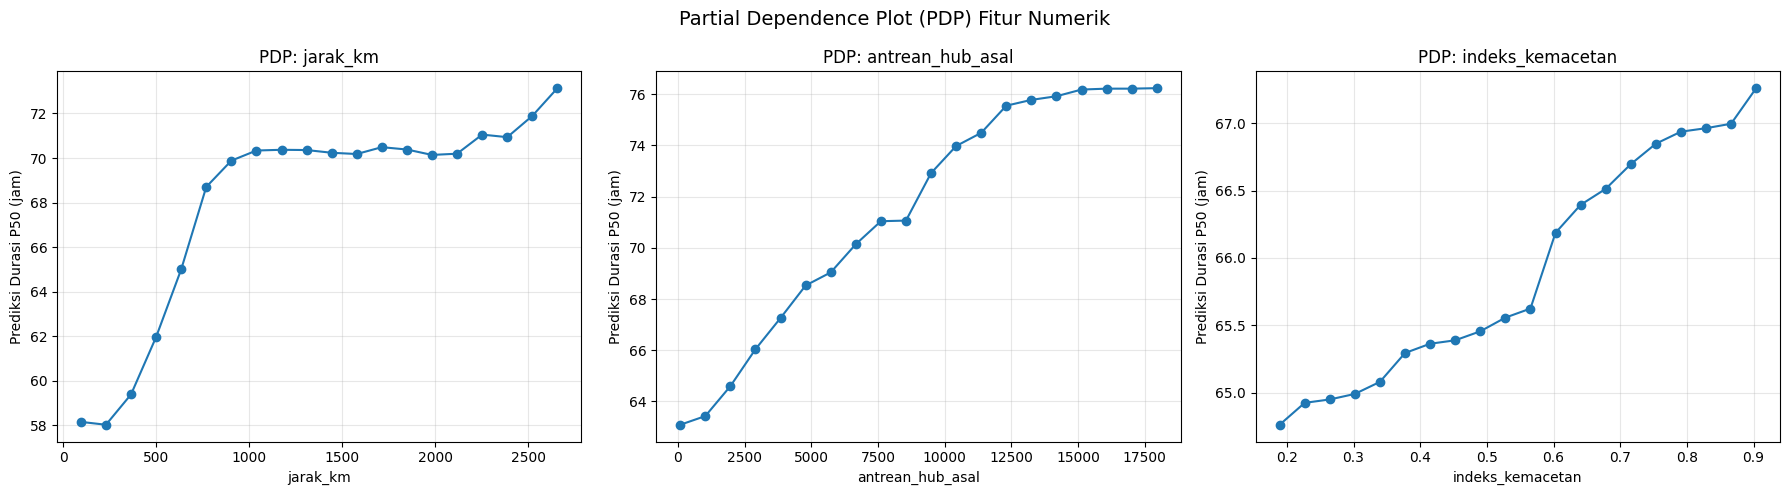

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Mengambil sampel data agar proses PDP lebih ringan
X_pdp = X_valid.sample(
    n=min(2000, len(X_valid)),
    random_state=42
).copy()

fitur_pdp = [
    "jarak_km",
    "antrean_hub_asal",
    "indeks_kemacetan"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, fitur in zip(axes, fitur_pdp):

    # Membatasi rentang pada persentil 5% sampai 95%
    batas_bawah = X_valid[fitur].quantile(0.05)
    batas_atas = X_valid[fitur].quantile(0.95)

    # Membuat 20 titik nilai fitur
    nilai_fitur = np.linspace(
        batas_bawah,
        batas_atas,
        20
    )

    hasil_pdp = []

    for nilai in nilai_fitur:
        data_pdp = X_pdp.copy()
        data_pdp[fitur] = nilai

        prediksi = model_p50.predict(data_pdp)
        hasil_pdp.append(np.mean(prediksi))

    # Membuat grafik
    ax.plot(nilai_fitur, hasil_pdp, marker="o")
    ax.set_title(f"PDP: {fitur}")
    ax.set_xlabel(fitur)
    ax.set_ylabel("Prediksi Durasi P50 (jam)")
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Partial Dependence Plot (PDP) Fitur Numerik",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:

# Menentukan kolom yang tidak digunakan sebagai fitur
drop_cols = ["id_paket", "jumlah_scan", "durasi_jam"]

# Memisahkan fitur dan target data training
X_final = df_train.drop(columns=drop_cols)
y_final = df_train["durasi_jam"]

# Mengambil fitur data testing
X_test_final = df_test.drop(
    columns=["id_paket", "jumlah_scan"]
)

# Melakukan feature engineering
X_final = feature_engineering(X_final)
X_test_final = feature_engineering(X_test_final)

# Mengidentifikasi fitur kategorikal
categorical_features = X_final.select_dtypes(
    include=["object"]
).columns.tolist()

# Menangani nilai kosong pada fitur kategorikal
for col in categorical_features:
    X_final[col] = X_final[col].fillna("UNKNOWN").astype(str)
    X_test_final[col] = X_test_final[col].fillna("UNKNOWN").astype(str)

# Memeriksa hasil persiapan data
print("Jumlah data training:", X_final.shape)
print("Jumlah data testing:", X_test_final.shape)
print("Jumlah fitur:", X_final.shape[1])
print("Jumlah fitur kategorikal:", len(categorical_features))
print("Jumlah missing value training:", X_final.isna().sum().sum())
print("Jumlah missing value testing:", X_test_final.isna().sum().sum())


Jumlah data training: (250000, 79)
Jumlah data testing: (60000, 79)
Jumlah fitur: 79
Jumlah fitur kategorikal: 6
Jumlah missing value training: 13897
Jumlah missing value testing: 3265


In [ ]:

from catboost import CatBoostRegressor

# Model final untuk prediksi P50
model_p50_final = CatBoostRegressor(
    iterations=813,
    learning_rate=0.05,
    depth=8,
    loss_function="Quantile:alpha=0.5",
    random_seed=42,
    verbose=100
)

# Melatih model menggunakan seluruh data training
model_p50_final.fit(
    X_final,
    y_final,
    cat_features=categorical_features
)

print("Model final P50 berhasil dilatih.")


0:	learn: 16.1109856	total: 736ms	remaining: 9m 57s
100:	learn: 10.1750125	total: 1m 14s	remaining: 8m 46s
200:	learn: 9.8075272	total: 2m 30s	remaining: 7m 38s
300:	learn: 9.6697007	total: 3m 47s	remaining: 6m 27s
400:	learn: 9.5982283	total: 5m 5s	remaining: 5m 13s
500:	learn: 9.5472584	total: 6m 24s	remaining: 3m 59s
600:	learn: 9.4999599	total: 7m 42s	remaining: 2m 43s
700:	learn: 9.4584573	total: 9m 4s	remaining: 1m 26s
800:	learn: 9.4202552	total: 10m 26s	remaining: 9.38s
812:	learn: 9.4150678	total: 10m 36s	remaining: 0us
Model final P50 berhasil dilatih.


In [ ]:

# Model final untuk prediksi P90
model_p90_final = CatBoostRegressor(
    iterations=256,
    learning_rate=0.05,
    depth=8,
    loss_function="Quantile:alpha=0.9",
    random_seed=42,
    verbose=100
)

# Melatih model menggunakan seluruh data training
model_p90_final.fit(
    X_final,
    y_final,
    cat_features=categorical_features
)

print("Model final P90 berhasil dilatih.")


0:	learn: 14.3835482	total: 903ms	remaining: 3m 50s
100:	learn: 10.0162509	total: 1m 12s	remaining: 1m 50s
200:	learn: 9.8569946	total: 2m 28s	remaining: 40.6s
255:	learn: 9.8028221	total: 3m 10s	remaining: 0us
Model final P90 berhasil dilatih.


In [ ]:

# Prediksi P50 dan P90 pada data testing
prediksi_test_p50 = model_p50_final.predict(X_test_final)
prediksi_test_p90 = model_p90_final.predict(X_test_final)

# Memeriksa hasil prediksi
print("Jumlah prediksi P50:", len(prediksi_test_p50))
print("Jumlah prediksi P90:", len(prediksi_test_p90))

print("\nStatistik prediksi P50:")
print(pd.Series(prediksi_test_p50).describe().round(2))

print("\nStatistik prediksi P90:")
print(pd.Series(prediksi_test_p90).describe().round(2))


Jumlah prediksi P50: 60000
Jumlah prediksi P90: 60000

Statistik prediksi P50:
count    60000.00
mean        69.91
std         32.22
min         13.54
25%         47.82
50%         62.58
75%         83.65
max        339.73
dtype: float64

Statistik prediksi P90:
count    60000.00
mean        94.25
std         46.53
min         16.34
25%         63.73
50%         82.86
75%        110.93
max        755.62
dtype: float64


In [ ]:

# Nilai kalibrasi P90 dari hasil validasi sebelumnya
delta_p90 = 4.992466301847685

# Menerapkan koreksi kalibrasi
prediksi_test_p90_kalibrasi = prediksi_test_p90 + delta_p90

# Memeriksa apakah terdapat prediksi P90 lebih kecil dari P50
jumlah_crossing = np.sum(
    prediksi_test_p90_kalibrasi < prediksi_test_p50
)

print("Jumlah crossing sebelum koreksi:", jumlah_crossing)

# Memastikan P90 tidak lebih kecil daripada P50
prediksi_test_p90_final = np.maximum(
    prediksi_test_p90_kalibrasi,
    prediksi_test_p50
)

# Memeriksa kembali hasilnya
jumlah_crossing_final = np.sum(
    prediksi_test_p90_final < prediksi_test_p50
)

print("Jumlah crossing setelah koreksi:", jumlah_crossing_final)
print("Rata-rata P90 setelah kalibrasi:",
      round(prediksi_test_p90_final.mean(), 2))
print("Rata-rata P50:",
      round(prediksi_test_p50.mean(), 2))


Jumlah crossing sebelum koreksi: 1
Jumlah crossing setelah koreksi: 0
Rata-rata P90 setelah kalibrasi: 99.24
Rata-rata P50: 69.91


In [ ]:

# Membuat tabel hasil prediksi
hasil_prediksi_test = pd.DataFrame({
    "id_paket": df_test["id_paket"].values,
    "p50": prediksi_test_p50,
    "p90": prediksi_test_p90_final
})

# Memeriksa hasil tabel
print("Ukuran tabel:", hasil_prediksi_test.shape)

display(hasil_prediksi_test.head(10))

print("\nPemeriksaan nilai kosong:")
print(hasil_prediksi_test.isna().sum())

print("\nPemeriksaan duplikasi ID:")
print(hasil_prediksi_test["id_paket"].duplicated().sum())

print("\nPemeriksaan P90 >= P50:")
print(
    (hasil_prediksi_test["p90"] >= hasil_prediksi_test["p50"]).all()
)


Ukuran tabel: (60000, 3)


,id_paket,p50,p90
0,P83639399,56.202794,76.750390
1,P26553951,106.628659,154.598596
2,P32537117,63.965109,91.592210
3,P28750760,61.017688,88.974999
4,P96580009,50.772467,72.478959
5,P48017366,164.400778,232.488685
6,P43165236,68.309221,90.392038
7,P66505512,49.325273,71.186170
8,P46572172,98.923759,142.956235
9,P88334628,69.148785,86.359583



Pemeriksaan nilai kosong:
id_paket    0
p50         0
p90         0
dtype: int64

Pemeriksaan duplikasi ID:
0

Pemeriksaan P90 >= P50:
True


In [ ]:

# Menyimpan hasil prediksi ke file CSV
nama_file = "hasil_prediksi_regresi.csv"

hasil_prediksi_test.to_csv(
    nama_file,
    index=False
)

print("File berhasil disimpan:", nama_file)

# Memeriksa kembali file CSV
df_hasil_csv = pd.read_csv(nama_file)

print("Jumlah baris CSV:", len(df_hasil_csv))
print("Kolom CSV:", df_hasil_csv.columns.tolist())

display(df_hasil_csv.head())


File berhasil disimpan: hasil_prediksi_regresi.csv
Jumlah baris CSV: 60000
Kolom CSV: ['id_paket', 'p50', 'p90']


,id_paket,p50,p90
0,P83639399,56.202794,76.750390
1,P26553951,106.628659,154.598596
2,P32537117,63.965109,91.592210
3,P28750760,61.017688,88.974999
4,P96580009,50.772467,72.478959


In [ ]:

from google.colab import files

files.download("hasil_prediksi_regresi.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>